# Микротрещина при термомеханической нагрузке в необлучённой таблетке UO₂

**Как пользоваться.** Исполните ячейки по порядку в Colab/Jupyter. Примеры со случайной выборкой проверяют поведение уравнений. Параметры рассеяния, число участков и нормировочная длина — настройки численного опыта. Для интерпретации в физических единицах задайте размеры своего образца и измеренные входы. Маркеры на обзорной 3D-картинке показывают центры.

При полном запуске SEED = None выбирает новый seed. Его значение выводится и сохраняется в parameters.json под именем effective_seed. Чтобы повторить реализацию, введите это целое число в SEED и выполните все ячейки. Сохранённые в архиве примеры и изображения получены при SEED = 42.

## Источник исходных данных

**Базовый эксперимент.** Y. W. Rhee и соавт., *In-Situ Observation of Sintering Shrinkage of UO₂ Compacts Derived from Different Powder Routes*, KNS, 2015, § 2–3, рис. 3. Это та же работа, что использована в расчёте полостей. В ней определяли усадку прессовок разных порошковых маршрутов. Исходные габариты прессовки служат координатной рамкой демонстрации. [Исходная публикация](https://www.kns.org/files/pre_paper/34/15A-419%EC%9D%B4%EC%98%81%EC%9A%B0.pdf).

## 1. Физическая постановка и источники

В опытах с быстрым нагревом UO₂ наблюдалось растрескивание. Рассматриваем отклик внутренних затравок на заданное локальное растяжение. Поле температур и напряжений при конкретном производственном охлаждении должен дать тепломеханический расчёт. В проверке рассматривается однородное одноосное растяжение со случайной ориентацией затравок. Для внутренней круглой затравочной трещины в бесконечном упругом теле $K_I=2\sigma_n\sqrt{a/\pi}$. При $K_I/K_{IC}\ge1$ возможно начало роста. Размеры в файле — размеры исходных затравок. Критерий не задаёт длину выросшей трещины или её раскрытие. Для сомкнутых берегов используется положительная часть нормального напряжения.

- [Microwave process for sintering of uranium dioxide](https://www.sciencedirect.com/science/article/abs/pii/S002231150300521X)

- [K для круглой внутренней трещины, рис. 9.4–2b](https://materials.duke.edu/XCOURSES/ME83/X02_Mechanics.pdf)

- [Grain Boundary and Lattice Fracture Toughness of UO₂ Measured Using Small-Scale Mechanics](https://www.ornl.gov/publication/grain-boundary-and-lattice-fracture-toughness-uo2-measured-using-small-scale-mechanics)

## 2. Условия и параметры

**Для калибровки нужны:** Измеренные радиусы зародышей, ориентации, поле напряжений и трещиностойкость соответствующей стадии. Полезно разделить зародыши на границах зёрен и внутри зёрен, если есть EBSD и данные K_IC. Вблизи наружной поверхности требуется поправка на конечную геометрию.

CSV использует относительный исходный размер scale = размер / L0_UM; для поля плотности scale задаёт относительную неоднородность. Координаты могут быть измеренными. При отсутствии CSV выборка контрольная логнормальная, с единичным средним.

In [1]:
# Размеры исходной прессовки Rhee, в мм. Для спечённой замените фактически измеренными.
R_MM, H_MM = 5.15, 8.5
COUNTS = [25, 50, 100, 200]  # вложенные выборки расчётных точек или объектов
SEED = None  # целое число для воспроизводимости; None даёт новую реализацию
L0_UM = 1.0   # единица длины демонстрационной геометрии, не измерение UO₂
CV = 0.2      # проверочный относительный разброс, не оценка по статье
INPUT_CSV = None  # путь к CSV со столбцом scale; необязательно x_mm,y_mm,z_mm
OUTPUT_ROOT = 'uo2_defect_results'

LOAD = 1.0  # безразмерное sigma*sqrt(L0 в метрах)/K_IC
NAME='07_thermal_crack'
ROLE='crack'
RESULT_LABEL='Коэффициент KⅠ/KⅠс'

## 3. Случайная выборка и воспроизводимость

Один seed задаёт связанные варианты N. Каждый меньший набор является началом большего. Таблица измерений заменяет генерацию исходных размеров.

In [2]:
from pathlib import Path
from datetime import datetime
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
assert len(COUNTS)>0 and all(type(n) is int and n>0 for n in COUNTS)
assert min(R_MM,H_MM,L0_UM)>0 and np.isfinite([R_MM,H_MM,L0_UM,CV]).all() and CV>=0
N = max(COUNTS)
seed = int(np.random.SeedSequence().entropy) if SEED is None else SEED
print('Seed запуска:', seed)
rng, pos_rng = [np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(2)]
out = Path(OUTPUT_ROOT)/NAME/datetime.now().strftime('run_%Y%m%d_%H%M%S_%f')
out.mkdir(parents=True)
params = {k:v for k,v in list(globals().items()) if k.isupper() and isinstance(v,(str,float,int,list,type(None)))}
params['effective_seed'] = seed
(out/'parameters.json').write_text(json.dumps(params,ensure_ascii=False,indent=2),encoding='utf8')
sample = None
if INPUT_CSV is None:
    sigma = np.sqrt(np.log1p(CV**2))
    scale = rng.lognormal(-sigma**2/2,sigma,N)
else:
    sample = pd.read_csv(INPUT_CSV).iloc[:N].copy()
    if len(sample)!=N: raise ValueError('В таблице меньше строк, чем max(COUNTS)')
    scale = sample['scale'].to_numpy(dtype=float)
assert np.all(np.isfinite(scale)) and np.all(scale>0)

def place(bounds,check_overlap):
    coords = []
    use_positions = sample is not None and all(c in sample for c in ['x_mm','y_mm','z_mm'])
    if sample is not None and any(c in sample for c in ['x_mm','y_mm','z_mm']) and not use_positions:
        raise ValueError('Укажите все три координаты или только scale')
    for i,b in enumerate(bounds):
        if b>=min(R_MM,H_MM/2): raise ValueError('Объект не помещается при заданном масштабе')
        for attempt in range(1 if use_positions else 10000):
            if use_positions:
                point = sample.iloc[i][['x_mm','y_mm','z_mm']].to_numpy(float)
            else:
                angle = pos_rng.uniform(0,2*np.pi)
                r = (R_MM-b)*np.sqrt(pos_rng.random())
                point = np.array([r*np.cos(angle),r*np.sin(angle),pos_rng.uniform(b,H_MM-b)])
            fits = np.hypot(*point[:2])+b <= R_MM and b <= point[2] <= H_MM-b
            if fits and (not check_overlap or all(np.linalg.norm(point-q)>b+bounds[j] for j,q in enumerate(coords))):
                break
        else: raise ValueError('Проверьте пересечения, координаты и единицы длины')
        coords.append(point)
    return np.asarray(coords)

def spheres(relative_radius):
    return L0_UM*np.repeat(np.asarray(relative_radius)[:,None],3,axis=1)

extra = {}

## 4. Расчёт локального состояния

Формулы раздела 1 применяются к каждому участку. Контрольные равенства проверяют баланс или допустимые пределы результата.

In [3]:
assert LOAD>=0
# Изотропные нормали; при одноосном растяжении sigma_n = sigma*cos²(theta).
cos_theta = rng.uniform(-1,1,N)
azimuth = rng.uniform(0,2*np.pi,N)
sine = np.sqrt(1-cos_theta**2)
extra.update(nx=sine*np.cos(azimuth),ny=sine*np.sin(azimuth),nz=cos_theta)
stress_ratio = LOAD*cos_theta**2
value = 2*stress_ratio*np.sqrt(scale/np.pi)
extra['eligible_for_growth'] = value>=1
axes = np.column_stack([scale,scale,np.zeros(N)])*L0_UM
assert np.all(value>=0)
xyz = place(axes.max(axis=1)/1000,True)

## 5. Результаты по вариантам

Исходные и итоговые параметры записываются построчно в CSV. Мин. и макс. относятся к данной выборке.

In [4]:
assert np.isfinite(value).all() and np.isfinite(axes).all() and np.all(axes>=0)
data = pd.DataFrame(dict(site=np.arange(1,N+1),scale=scale,x_mm=xyz[:,0],y_mm=xyz[:,1],
                         z_mm=xyz[:,2],result=value,**extra))
if ROLE!='field':
    data[['a_um','b_um','c_um']] = axes
    data['volume_um3'] = 4*np.pi/3*np.prod(axes,axis=1)
data.to_csv(out/'sites.csv',index=False)
summaries = []
for n in sorted(set(COUNTS)):
    g = data.iloc[:n]
    g.to_csv(out/f'sites_N{n}.csv',index=False)
    row = dict(N=n,mean=g.result.mean(),minimum=g.result.min(),median=g.result.median(),
               maximum=g.result.max(),sd=g.result.std(ddof=1) if n>1 else np.nan)
    if 'volume_um3' in g and ROLE!='crack': row['sum_volume_um3']=g.volume_um3.sum()
    if ROLE=='crack': row['growth_criterion_met']=int(g.eligible_for_growth.sum())
    summaries.append(row)
summary = pd.DataFrame(summaries)
summary.to_csv(out/'summary.csv',index=False)
display(summary.round(5))

N,mean,minimum,median,maximum,sd,growth_criterion_met
25,0.32478,0.00460,0.25261,1.07031,0.30139,1
50,0.35031,0.00294,0.25684,1.07031,0.31104,3
100,0.35821,0.00033,0.30252,1.23346,0.32794,5
200,0.36390,0.00001,0.28484,1.23686,0.33154,10


## 6. Пространственное распределение и разброс

Цвет показывает рассчитанную характеристику. Интервал на правом графике — наблюдаемый размах.

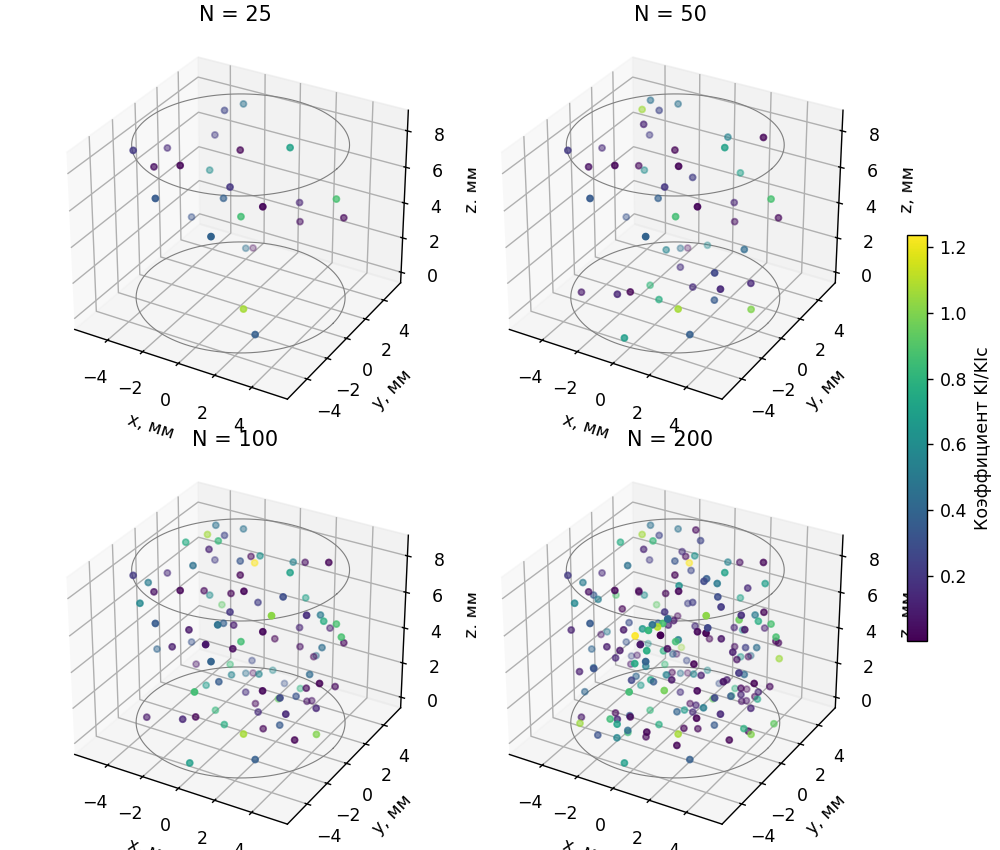

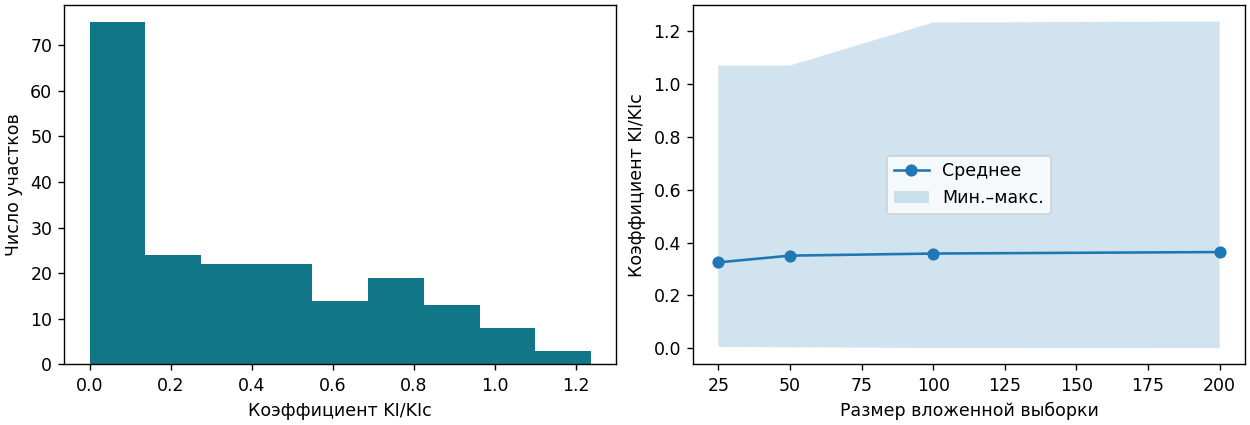

In [5]:
# Одна панель на каждый размер выборки; общая цветовая шкала и одинаковый ракурс.
counts = sorted(set(COUNTS))
fig = plt.figure(figsize=(8,3.4*((len(counts)+1)//2)),layout='constrained')
lo,hi = data.result.min(),data.result.max()
for j,n in enumerate(counts,1):
    ax = fig.add_subplot((len(counts)+1)//2,2,j,projection='3d')
    g = data.iloc[:n]
    t = np.linspace(0,2*np.pi,120)
    for z in [0,H_MM]:
        ax.plot(R_MM*np.cos(t),R_MM*np.sin(t),z,color='gray',lw=.65)
    sc=ax.scatter(g.x_mm,g.y_mm,g.z_mm,c=g.result,cmap='viridis',s=12,
                  vmin=lo,vmax=hi if hi>lo else lo+1e-9)
    ax.set(xlabel='x, мм',ylabel='y, мм',zlabel='z, мм',title=f'N = {n}')
    ax.set_box_aspect((2*R_MM,2*R_MM,H_MM))
fig.colorbar(sc,ax=fig.axes,shrink=.5,label=RESULT_LABEL)
fig.savefig(out/'geometry.png',dpi=125); plt.close(fig)
display(Image(filename=str(out/'geometry.png')))
fig,(a,b) = plt.subplots(1,2,figsize=(10,3.4),layout='constrained')
hist_values = data.result if not np.isclose(lo,hi) else np.full(len(data),float(lo))
a.hist(hist_values,bins='auto',color='#117788')
a.set(xlabel=RESULT_LABEL,ylabel='Число участков')
b.plot(summary.N,summary['mean'],'o-',label='Среднее')
b.fill_between(summary.N.to_numpy(),summary.minimum.to_numpy(),summary.maximum.to_numpy(),alpha=.2,label='Мин.–макс.')
b.set(xlabel='Размер вложенной выборки',ylabel=RESULT_LABEL)
b.legend()
fig.savefig(out/'distribution.png',dpi=125); plt.close(fig)
display(Image(filename=str(out/'distribution.png')))

## 7. Прямой экспорт STEP

Последняя ячейка создаёт `model_N*.step` для всех заданных N. При первом запуске ячейка установит CadQuery, если его ещё нет в текущем окружении Python. Интернет нужен для скачивания пакета. Координаты и размеры STEP заданы в миллиметрах.

Полости вычитаются из цилиндра. Трещины записываются как внутренние дисковые поверхности нулевой толщины. Для моделирования разрыва задайте соответствующие условия на границах в COMSOL. Включения входят в STEP как отдельные материальные тела с соответствующими вырезами в матрице.


In [6]:
from importlib.util import find_spec
from pathlib import Path
import subprocess
import sys

# Устанавливаем CAD-ядро в текущее окружение Python при первом запуске.
if find_spec("cadquery") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "cadquery==2.7.0"])
import cadquery as cq
from OCP.BRep import BRep_Builder
from OCP.TopoDS import TopoDS_Solid
from OCP.IFSelect import IFSelect_RetDone


def make_spheroid(a, b, c, center):
    # Полуоси заданы в мм. Вращение дуги эллипса даёт точный сфероид.
    if a != b:
        raise ValueError("Для сфероида полуоси a и b должны совпадать")
    if a == c:
        return cq.Solid.makeSphere(a, center, angleDegrees1=-90)
    edge = cq.Edge.makeEllipse(a, c, dir=(0, -1, 0), angle1=-90, angle2=90)
    diameter = cq.Edge.makeLine(edge.endPoint(), edge.startPoint())
    meridian = cq.Wire.assembleEdges([edge, diameter])
    return cq.Solid.revolve(meridian, [], 360, (0, 0, 0), (0, 0, 1)).translate(center)


def export_geometry(data, counts, role, radius_mm, height_mm, directory):
    for n in sorted(set(counts)):
        cylinder = cq.Solid.makeCylinder(radius_mm, height_mm)
        features = []
        for row in data.iloc[:n].itertuples(index=False):
            center = cq.Vector(row.x_mm, row.y_mm, row.z_mm)
            a, b, c = (value / 1000 for value in (row.a_um, row.b_um, row.c_um))
            if role == "crack":
                normal = (row.nx, row.ny, row.nz)
                disk = cq.Face.makeFromWires(cq.Wire.makeCircle(a, center, normal))
                features.append(disk)
            elif min(a, b, c) > 0:
                features.append(make_spheroid(a, b, c, center))

        if role == "crack":
            model = cq.Compound.makeCompound([cylinder, *features])
        elif features:
            # Полости разнесены и лежат внутри цилиндра: добавляем оболочки
            # с обратной ориентацией к единственному телу матрицы.
            builder = BRep_Builder()
            solid = TopoDS_Solid()
            builder.MakeSolid(solid)
            builder.Add(solid, cylinder.Shells()[0].wrapped)
            for feature in features:
                builder.Add(solid, feature.Shells()[0].wrapped.Reversed())
            matrix = cq.Solid(solid)
            if len(matrix.Solids()) != 1 or len(matrix.Shells()) != len(features) + 1:
                raise RuntimeError(f"N={n}: вычитание изменило ожидаемое число полостей")
            model = cq.Compound.makeCompound([matrix, *features]) if role == "inclusion" else matrix
        else:
            model = cylinder

        if not features and not cylinder.isValid():
            raise RuntimeError(f"N={n}: CAD-геометрия не прошла проверку")
        path = Path(directory) / f"model_N{n}.step"
        temporary = path.with_suffix(".tmp.step")
        status = model.exportStep(str(temporary))
        if status != IFSelect_RetDone:
            raise RuntimeError(f"N={n}: ошибка записи STEP ({status})")
        temporary.replace(path)
        print(path)


export_geometry(data, COUNTS, ROLE, R_MM, H_MM, out)


examples/07_thermal_crack/model_N25.step
examples/07_thermal_crack/model_N50.step
examples/07_thermal_crack/model_N100.step
examples/07_thermal_crack/model_N200.step
